In [1]:
import yfinance as yf
import pandas as pd
import warnings
warnings.filterwarnings("ignore", category=pd.errors.Pandas4Warning)


In [2]:
tickers = ["WEGE3.SA", "VULC3.SA"]

dados = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-11-12",
    interval="1d",
    auto_adjust=False,
    progress=False
)

print(dados.head())
print(dados.columns)


Price      Adj Close                Close                 High             \
Ticker      VULC3.SA   WEGE3.SA  VULC3.SA   WEGE3.SA  VULC3.SA   WEGE3.SA   
Date                                                                        
2020-01-02  5.207673  15.458447  8.880052  17.620001  9.235254  17.735001   
2020-01-03  5.109307  15.261046  8.712317  17.395000  8.919519  17.625000   
2020-01-06  5.196101  15.300523  8.860318  17.440001  8.899785  17.549999   
2020-01-07  5.201886  15.418969  8.870185  17.575001  9.077386  17.584999   
2020-01-08  5.201886  14.835546  8.870185  16.910000  9.047786  17.610001   

Price            Low                 Open              Volume           
Ticker      VULC3.SA   WEGE3.SA  VULC3.SA   WEGE3.SA VULC3.SA WEGE3.SA  
Date                                                                    
2020-01-02  8.880052  17.360001  9.087253  17.450001  1189148  5876000  
2020-01-03  8.564316  17.334999  8.820851  17.500000  1930022  7345800  
2020-01-06  8.6531

In [3]:

precos = dados["Close"]
precos_ajustados = dados["Adj Close"]
volumes = dados["Volume"]

print("PREÇOS:")
print(precos.head())

print("\nVOLUMES:")
print(volumes.head())

print("\nVALORES AUSENTES:")
print(dados.isna().sum())


PREÇOS:
Ticker      VULC3.SA   WEGE3.SA
Date                           
2020-01-02  8.880052  17.620001
2020-01-03  8.712317  17.395000
2020-01-06  8.860318  17.440001
2020-01-07  8.870185  17.575001
2020-01-08  8.870185  16.910000

VOLUMES:
Ticker      VULC3.SA  WEGE3.SA
Date                          
2020-01-02   1189148   5876000
2020-01-03   1930022   7345800
2020-01-06    742901   6366600
2020-01-07    552868   6303600
2020-01-08    699522   8153800

VALORES AUSENTES:
Price      Ticker  
Adj Close  VULC3.SA    0
           WEGE3.SA    0
Close      VULC3.SA    0
           WEGE3.SA    0
High       VULC3.SA    0
           WEGE3.SA    0
Low        VULC3.SA    0
           WEGE3.SA    0
Open       VULC3.SA    0
           WEGE3.SA    0
Volume     VULC3.SA    0
           WEGE3.SA    0
dtype: int64


In [4]:
volume_financeiro = precos * volumes
print(volume_financeiro.head())


Ticker          VULC3.SA      WEGE3.SA
Date                                  
2020-01-02  1.055970e+07  1.035351e+08
2020-01-03  1.681496e+07  1.277802e+08
2020-01-06  6.582339e+06  1.110335e+08
2020-01-07  4.904041e+06  1.107858e+08
2020-01-08  6.204889e+06  1.378808e+08


In [5]:

ultimos_252 = volume_financeiro.tail(252)

liquidez_media = ultimos_252.mean()

print(liquidez_media)


Ticker
VULC3.SA    2.622513e+07
WEGE3.SA    4.190004e+08
dtype: float64


In [6]:
print("Primeira data:", dados.index.min())
print("Última data:", dados.index.max())
print("Quantidade de pregões:", len(dados))

print("\nValores ausentes em Volume:")
print(volumes.isna().sum())

print("\nVolumes zerados:")
print((volumes == 0).sum())

Primeira data: 2020-01-02 00:00:00
Última data: 2026-11-11 00:00:00
Quantidade de pregões: 1709

Valores ausentes em Volume:
Ticker
VULC3.SA    0
WEGE3.SA    0
dtype: int64

Volumes zerados:
Ticker
VULC3.SA    0
WEGE3.SA    1
dtype: int64


In [7]:
# Identificar a data com volume zero
datas_zero = volumes.index[volumes["WEGE3.SA"] == 0]

print(datas_zero)

# Ver os dados completos nessas datas
print(dados.loc[datas_zero])

DatetimeIndex(['2022-09-26'], dtype='datetime64[s]', name='Date', freq=None)
Price      Adj Close                Close                High           \
Ticker      VULC3.SA  WEGE3.SA   VULC3.SA WEGE3.SA   VULC3.SA WEGE3.SA   
Date                                                                     
2022-09-26  8.458344  27.79369  13.912081    30.57  14.405417    30.57   

Price             Low                Open            Volume           
Ticker       VULC3.SA WEGE3.SA   VULC3.SA WEGE3.SA VULC3.SA WEGE3.SA  
Date                                                                  
2022-09-26  13.912081    30.57  14.405417    30.57   314085        0  


In [8]:
dados.loc["2022-09-22":"2022-09-28", 
          [("Close", "WEGE3.SA"), ("Volume", "WEGE3.SA")]]

Price,Close,Volume
Ticker,WEGE3.SA,WEGE3.SA
Date,,
2022-09-22,31.010000,8889000
2022-09-23,30.570000,5895500
2022-09-26,30.570000,0
2022-09-27,30.049999,7256200
2022-09-28,30.320000,5869400


In [9]:
precos_ajustados_limpos = precos_ajustados.copy()

precos_ajustados_limpos.loc["2022-09-26", "WEGE3.SA"] = float("nan")

In [10]:
retornos = precos_ajustados_limpos.pct_change(fill_method=None)

In [11]:
print(retornos.loc["2022-09-22":"2022-09-29"])
print("\nValores ausentes:")
print(retornos.isna().sum())

Ticker      VULC3.SA  WEGE3.SA
Date                          
2022-09-22  0.035441 -0.005452
2022-09-23 -0.013423 -0.014189
2022-09-26 -0.040816       NaN
2022-09-27  0.004964       NaN
2022-09-28  0.005645  0.008985
2022-09-29 -0.001403 -0.005937

Valores ausentes:
Ticker
VULC3.SA    1
WEGE3.SA    3
dtype: int64


In [12]:
retornos_validos = retornos.dropna()

print(retornos_validos.head())
print("Observações válidas:", len(retornos_validos))

Ticker      VULC3.SA  WEGE3.SA
Date                          
2020-01-03 -0.018889 -0.012770
2020-01-06  0.016987  0.002587
2020-01-07  0.001113  0.007741
2020-01-08  0.000000 -0.037838
2020-01-09 -0.001112 -0.014784
Observações válidas: 1706


In [13]:
correlacao = retornos_validos.corr()

print(correlacao)

Ticker    VULC3.SA  WEGE3.SA
Ticker                      
VULC3.SA  1.000000  0.275916
WEGE3.SA  0.275916  1.000000


In [14]:
retornos_medios = retornos_validos.mean()

volatilidades = retornos_validos.std()

covariancias = retornos_validos.cov()

print("Retornos médios diários:")
print(retornos_medios)

print("\nVolatilidades diárias:")
print(volatilidades)

print("\nMatriz de covariância:")
print(covariancias)

Retornos médios diários:
Ticker
VULC3.SA    0.000833
WEGE3.SA    0.000979
dtype: float64

Volatilidades diárias:
Ticker
VULC3.SA    0.025400
WEGE3.SA    0.022895
dtype: float64

Matriz de covariância:
Ticker    VULC3.SA  WEGE3.SA
Ticker                      
VULC3.SA  0.000645  0.000160
WEGE3.SA  0.000160  0.000524


In [15]:
import numpy as np

# Ordem: VULC3, WEGE3
ativos = ["VULC3.SA", "WEGE3.SA"]

mu = retornos_validos[ativos].mean()
Sigma = retornos_validos[ativos].cov()

# Elementos da matriz de covariância
var1 = Sigma.iloc[0, 0]
var2 = Sigma.iloc[1, 1]
cov12 = Sigma.iloc[0, 1]

# Pesos da carteira de mínima variância
w1 = (var2 - cov12) / (var1 + var2 - 2 * cov12)
w1 = np.clip(w1, 0, 1)  # Sem vendas a descoberto
w2 = 1 - w1

w = np.array([w1, w2])

# Retorno esperado e volatilidade da carteira
retorno_carteira = w @ mu.to_numpy()
variancia_carteira = w @ Sigma.to_numpy() @ w
volatilidade_carteira = np.sqrt(variancia_carteira)

print(f"Peso Vulcabras: {w1:.2%}")
print(f"Peso WEG: {w2:.2%}")

print(f"\nRetorno médio diário: {retorno_carteira:.4%}")
print(f"Volatilidade diária: {volatilidade_carteira:.4%}")

print(f"\nVolatilidade Vulcabras: {np.sqrt(var1):.4%}")
print(f"Volatilidade WEG: {np.sqrt(var2):.4%}")

Peso Vulcabras: 42.87%
Peso WEG: 57.13%

Retorno médio diário: 0.0917%
Volatilidade diária: 1.9190%

Volatilidade Vulcabras: 2.5400%
Volatilidade WEG: 2.2895%


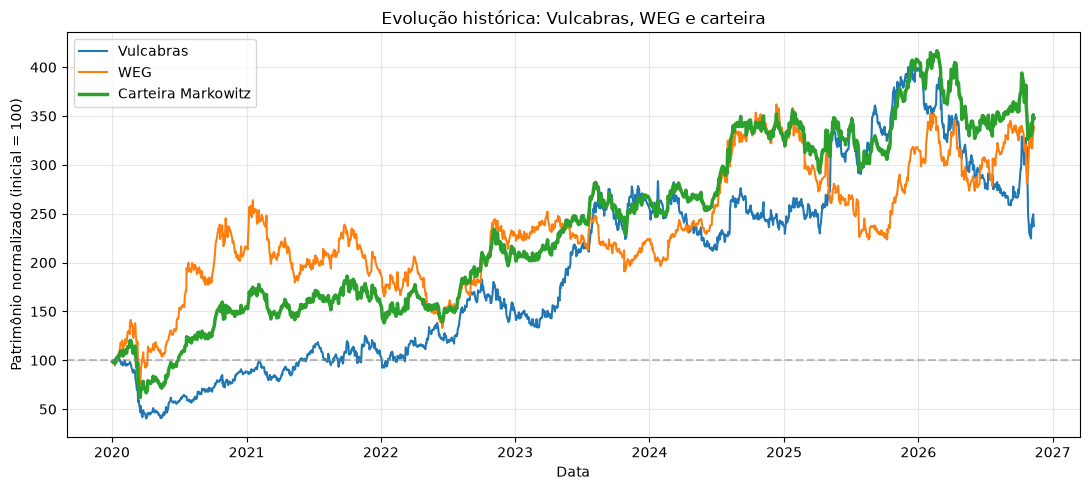

In [16]:

import matplotlib.pyplot as plt
import pandas as pd

# Retornos diários das duas ações
retornos_ativos = retornos_validos[["VULC3.SA", "WEGE3.SA"]]

# Retorno diário da carteira com pesos constantes
retornos_carteira = (
    w1 * retornos_ativos["VULC3.SA"]
    + w2 * retornos_ativos["WEGE3.SA"]
)

# Evolução acumulada começando em 100
evolucao = (1 + retornos_ativos).cumprod() * 100
evolucao["Carteira Markowitz"] = (
    (1 + retornos_carteira).cumprod() * 100
)

# Gráfico
plt.figure(figsize=(11, 5))

plt.plot(evolucao.index, evolucao["VULC3.SA"],
         label="Vulcabras")

plt.plot(evolucao.index, evolucao["WEGE3.SA"],
         label="WEG")

plt.plot(evolucao.index, evolucao["Carteira Markowitz"],
         label="Carteira Markowitz", linewidth=2.5)

plt.axhline(100, linestyle="--", color="gray", alpha=0.5)

plt.title("Evolução histórica: Vulcabras, WEG e carteira")
plt.xlabel("Data")
plt.ylabel("Patrimônio normalizado (inicial = 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


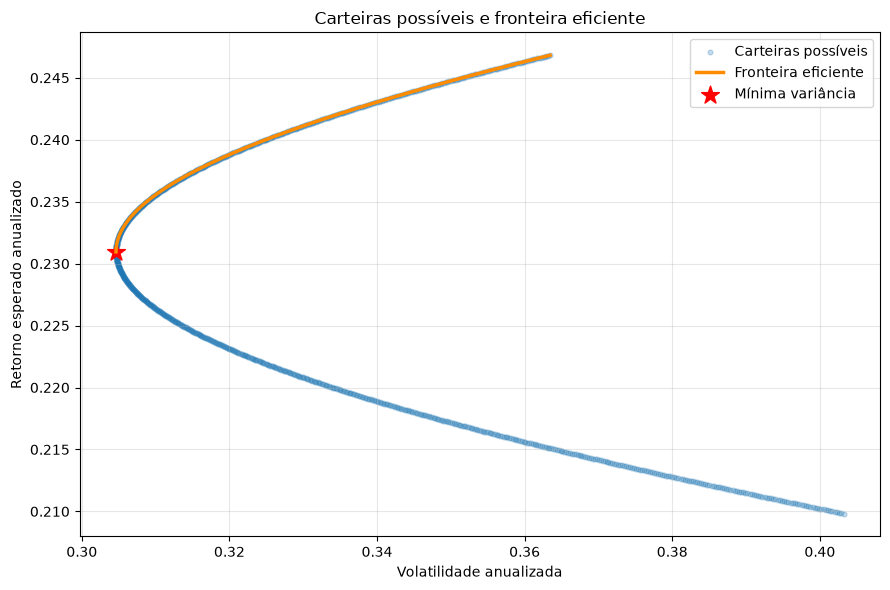

Peso de VULC3.SA na carteira de mínima variância: 42.90%
Peso de WEGE3.SA na carteira de mínima variância: 57.10%


In [17]:
# Fronteira eficiente para os dois ativos do teste
# Pressupõe que as células anteriores já criaram `retornos_validos` e `ativos`.
import numpy as np
import matplotlib.pyplot as plt

retornos_dois_ativos = retornos_validos[ativos].dropna()
mu_diario = retornos_dois_ativos.mean().to_numpy()
cov_diaria = retornos_dois_ativos.cov().to_numpy()

# Variamos o peso do primeiro ativo; o peso do segundo é o que falta para 100%.
peso_1 = np.linspace(0, 1, 1001)
pesos = np.column_stack([peso_1, 1 - peso_1])

retornos_diarios_carteiras = pesos @ mu_diario
variancias_diarias = np.einsum('ij,jk,ik->i', pesos, cov_diaria, pesos)
volatilidades_diarias = np.sqrt(np.maximum(variancias_diarias, 0))

# Anualização aproximada para dados diários (252 pregões por ano).
retornos_anuais = retornos_diarios_carteiras * 252
volatilidades_anuais = volatilidades_diarias * np.sqrt(252)

# Destaca os pontos não dominados: não existe outra carteira com risco menor
# ou igual e retorno maior ou igual.
ordem = np.lexsort((-retornos_anuais, volatilidades_anuais))
indices_eficientes = []
maior_retorno_ate_agora = -np.inf
for i in ordem:
    if retornos_anuais[i] > maior_retorno_ate_agora + 1e-12:
        indices_eficientes.append(i)
        maior_retorno_ate_agora = retornos_anuais[i]

indices_eficientes = np.array(indices_eficientes)
ordem_fronteira = indices_eficientes[np.argsort(volatilidades_anuais[indices_eficientes])]

# Carteira de menor volatilidade entre as combinações testadas.
indice_min_variancia = np.argmin(volatilidades_anuais)

plt.figure(figsize=(9, 6))
plt.scatter(volatilidades_anuais, retornos_anuais,
            s=12, alpha=0.25, label='Carteiras possíveis')
plt.plot(volatilidades_anuais[ordem_fronteira],
         retornos_anuais[ordem_fronteira],
         color='darkorange', linewidth=2.5, label='Fronteira eficiente')
plt.scatter(volatilidades_anuais[indice_min_variancia],
            retornos_anuais[indice_min_variancia],
            color='red', marker='*', s=180, label='Mínima variância')
plt.xlabel('Volatilidade anualizada')
plt.ylabel('Retorno esperado anualizado')
plt.title('Carteiras possíveis e fronteira eficiente')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Peso de {ativos[0]} na carteira de mínima variância: {pesos[indice_min_variancia, 0]:.2%}")
print(f"Peso de {ativos[1]} na carteira de mínima variância: {pesos[indice_min_variancia, 1]:.2%}")
